# Whole-section molecular comparison

Compare six young and six old mouse hearts using all measured pixels. The
extraction already calculated each mouse's mean spectrum at native resolution.
Summing those means into a common mass grid gives the same result as binning
every pixel spectrum and then averaging. Each mouse receives equal weight in
the comparison.

The ranking is descriptive. A mass window may contain multiple signals, and
whole-section averages can reflect differences in which tissue was measured.
Use the ranked windows to choose full-pixel maps for review.

In [1]:
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd().resolve()
if not (root / "pyproject.toml").exists():
    root = root.parent
assert (root / "pyproject.toml").exists(), "Open the notebook from the repository."
sys.path.insert(0, str(root / "src"))
from cardiac_aging.inspection import load_config

config = load_config(root)
# Override this path with CARDIAC_MSI_FEATURES if the extracted data move.
default_features = Path.home() / "Documents/Codex/2026-11-03/can-x20/work/full-msi"
features = Path(os.environ.get("CARDIAC_MSI_FEATURES", str(default_features)))
results = root / config["results_dir"]
results.mkdir(parents=True, exist_ok=True)
samples = pd.read_csv(root / config["sample_sheet"], dtype={"measurement_id": str})
assert samples["animal_id"].nunique() == len(samples) == 12
assert samples["age_group"].value_counts().to_dict() == {"young": 6, "old": 6}

mean_spectra, coverage = [], []
common_edges = np.arange(6000, 20001) / 10  # 600.0 to 2000.0 in 0.10 m/z steps
for sample in samples.itertuples(index=False):
    folder = features / sample.measurement_id
    info = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
    if (info["preview"] or info["pixels_processed"] != info["pixels_declared"]
            or info["measurement_id"] != sample.measurement_id
            or info["source"] != sample.imzml_filename):
        raise ValueError(f"Unexpected extraction metadata for {sample.measurement_id}")
    with np.load(folder / "axes_and_native_mean.npz") as arrays:
        mz, mean = arrays["mz"], arrays["native_mean"]
        edges = common_edges
        starts = np.searchsorted(mz, edges[:-1])
        if (starts[0] != 0 or starts[-1] >= len(mz) or not np.all(np.diff(starts) > 0)
                or mz[-1] != edges[-1] or not np.isfinite(mean).all()):
            raise ValueError(f"Invalid mass axis or spectrum for {sample.measurement_id}")
        binned_mean = np.add.reduceat(mean, starts)
        np.testing.assert_allclose(binned_mean.sum(), mean.sum(), rtol=1e-12)
        mean_spectra.append(binned_mean)
    coverage.append(info["pixels_processed"])

intensity = np.stack(mean_spectra)
samples["pixels_used"] = coverage
display(samples[["measurement_id", "animal_id", "age_group", "pixels_used"]])
print(f"{sum(coverage):,} pixels represented in {len(samples)} mouse-level spectra.")

,measurement_id,animal_id,age_group,pixels_used
0,1465,Lux10,young,49973
1,1466,Lux11,young,67228
2,1467,Lux12,young,69540
3,1468,Lux16,young,96297
4,1469,Lux17,young,83903
5,1470,Lux18,young,71670
6,1471,Lux13,old,78259
7,1472,Lux14,old,88747
8,1473,Lux15,old,124191
9,1474,Lux19,old,101798


1,038,886 pixels represented in 12 mouse-level spectra.


In [2]:
is_old = samples["age_group"].eq("old").to_numpy()
young, old = intensity[~is_old], intensity[is_old]
young_mean, old_mean = young.mean(axis=0), old.mean(axis=0)
difference = old_mean - young_mean
pooled_sd = np.sqrt((young.var(axis=0, ddof=1) + old.var(axis=0, ddof=1)) / 2)
standardized = np.divide(difference, pooled_sd,
                         out=np.full_like(difference, np.nan), where=pooled_sd > 0)

# Check whether removing any one mouse reverses the direction.
without_one = np.vstack([
    old_mean - (young.sum(axis=0) - young) / (len(young) - 1),
    (old.sum(axis=0) - old) / (len(old) - 1) - young_mean,
])
stable = np.all(np.sign(without_one) == np.sign(difference), axis=0) & (difference != 0)
windows = pd.DataFrame({
    "mz_lower": common_edges[:-1],
    "mz_upper": common_edges[1:],
    "young_mean": young_mean,
    "old_mean": old_mean,
    "old_minus_young": difference,
    "standardized_difference": standardized,
    "direction_stable_after_leaving_one_mouse_out": stable,
})
windows["absolute_standardized_difference"] = windows["standardized_difference"].abs()
windows = windows.sort_values("absolute_standardized_difference", ascending=False)
windows.to_csv(results / "whole_section_mass_windows.csv", index=False)
np.savez(results / "whole_section_mouse_spectra.npz", measurement_ids=samples["measurement_id"].to_numpy(dtype=str),
         age_groups=samples["age_group"].to_numpy(dtype=str), bin_edges=common_edges,
         intensity=intensity, pixels_used=coverage)

# Choose separated windows to avoid displaying several adjacent bins of one peak.
selected = []
for i in windows.index[windows["standardized_difference"].notna() & windows["direction_stable_after_leaving_one_mouse_out"]]:
    if all(abs(common_edges[i] - common_edges[j]) >= 1.0 for j in selected):
        selected.append(i)
    if len(selected) == 6:
        break
display(windows.loc[selected, ["mz_lower", "mz_upper", "young_mean", "old_mean",
                               "old_minus_young", "standardized_difference"]])

,mz_lower,mz_upper,young_mean,old_mean,old_minus_young,standardized_difference
4469,1046.9,1047.0,1.794087,2.057610,0.263523,3.033829
1743,774.3,774.4,4.006092,5.232630,1.226539,2.443017
817,681.7,681.8,2.598229,2.022416,-0.575813,-2.333161
654,665.4,665.5,4.764104,6.556434,1.792330,2.132979
113,611.3,611.4,4.175902,4.884374,0.708472,1.957412
5066,1106.6,1106.7,2.964996,3.942133,0.977137,1.920840


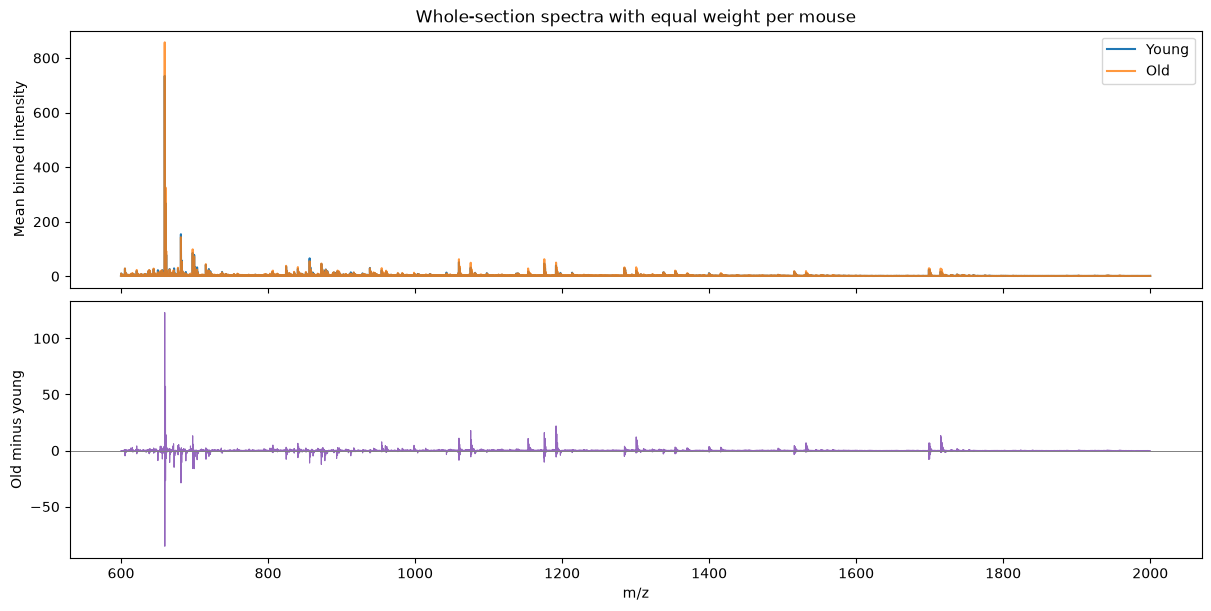

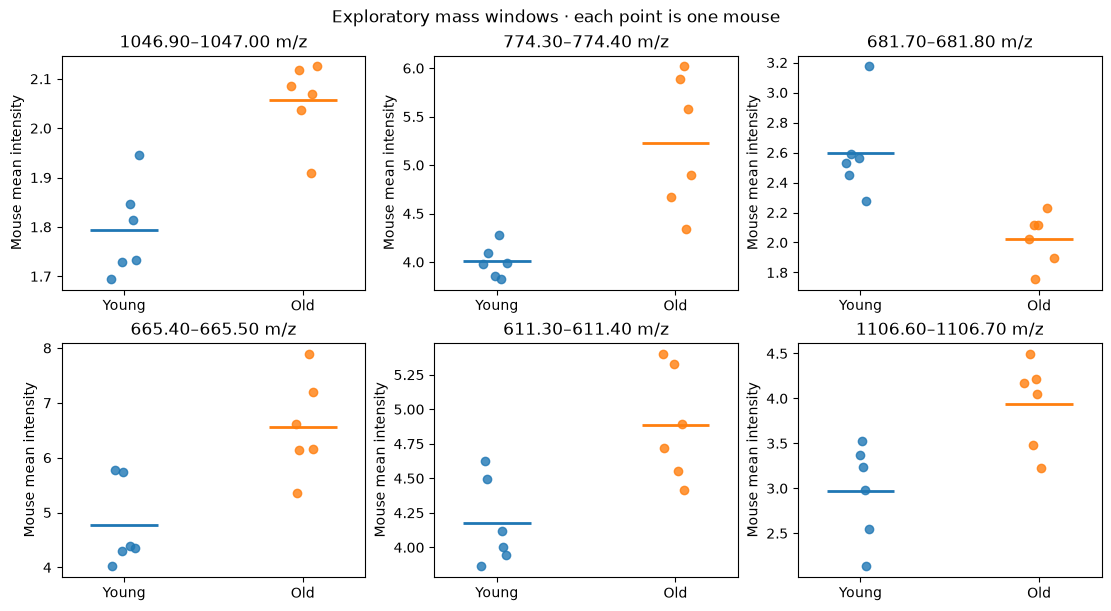

In [4]:
centers = (common_edges[:-1] + common_edges[1:]) / 2
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout="constrained")
axes[0].plot(centers, young_mean, color="tab:blue", label="Young")
axes[0].plot(centers, old_mean, color="tab:orange", label="Old", alpha=.8)
axes[0].set(ylabel="Mean binned intensity", title="Whole-section spectra with equal weight per mouse")
axes[0].legend()
axes[1].plot(centers, difference, color="tab:purple", linewidth=.8)
axes[1].axhline(0, color="gray", linewidth=.7)
axes[1].set(xlabel="m/z", ylabel="Old minus young")
fig.savefig(results / "whole_section_spectra.png", dpi=170)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
rng = np.random.default_rng(42)
for ax in axes.flat:
    ax.set_visible(False)
for ax, i in zip(axes.flat, selected):
    ax.set_visible(True)
    for x, values, color in [(0, young[:, i], "tab:blue"), (1, old[:, i], "tab:orange")]:
        ax.scatter(x + rng.uniform(-.09, .09, len(values)), values, color=color, alpha=.8)
        ax.hlines(values.mean(), x - .19, x + .19, color=color, linewidth=2)
    ax.set(xticks=[0, 1], xticklabels=["Young", "Old"],
           xlim=(-.35, 1.35), title=f"{common_edges[i]:.2f}–{common_edges[i+1]:.2f} m/z",
           ylabel="Mouse mean intensity")
fig.suptitle("Exploratory mass windows · each point is one mouse")
fig.savefig(results / "whole_section_candidate_windows.png", dpi=170)
plt.show()

## MS/MS target review · maximum intensity in 1 m/z windows

This review expands the selected 0.10 m/z screening windows to their enclosing
integer intervals. For each mouse, find the highest intensity and its m/z in
the half-open interval, then compare the six young and six old maxima.
The plots mark each maximum on its native-resolution spectrum.

The maxima can occur at different masses within an interval. The comparison
describes the strongest signal in that interval. The selected candidates and
their group differences are exploratory.


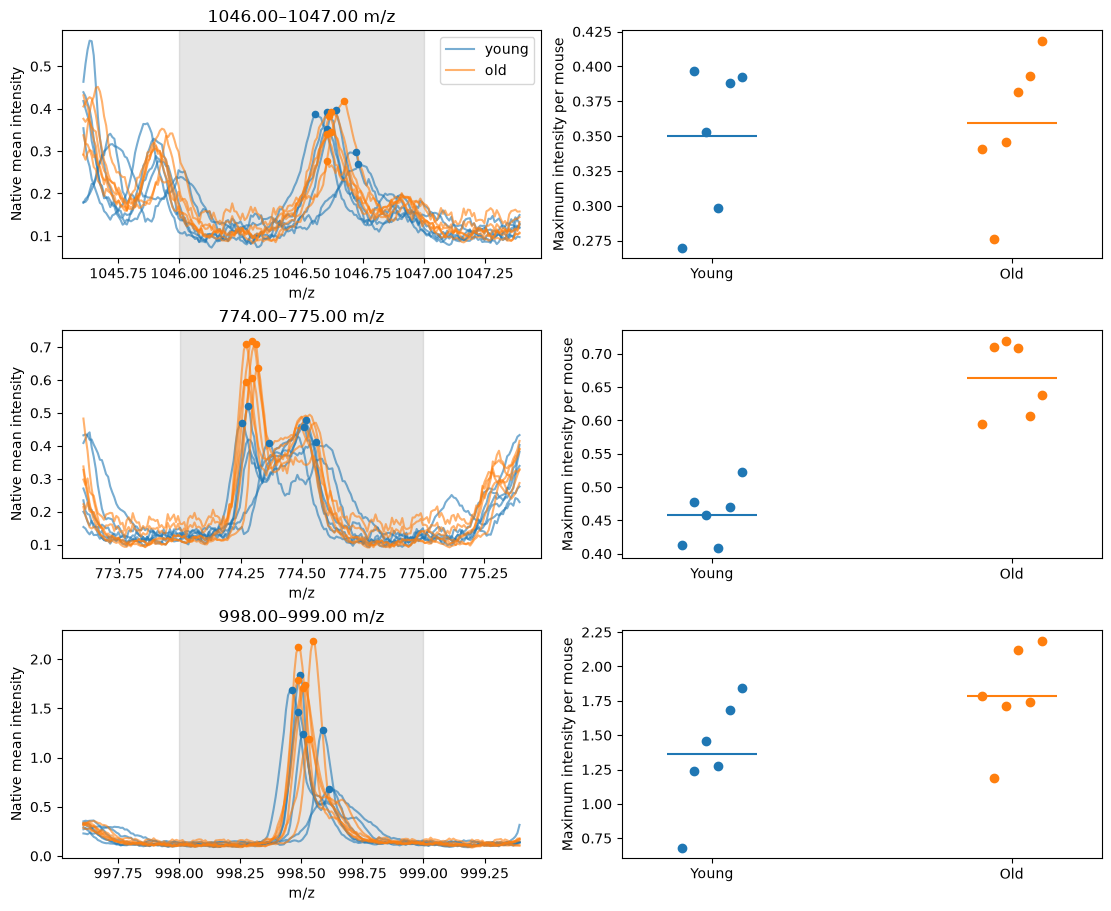

,measurement_id,age_group,1046.00–1047.00 max intensity,1046.00–1047.00 max m/z,774.00–775.00 max intensity,774.00–775.00 max m/z,998.00–999.00 max intensity,998.00–999.00 max m/z
0,1465,young,0.2699,1046.7325,0.4126,774.5590,0.6815,998.6148
1,1466,young,0.3967,1046.6395,0.4771,774.5167,1.2404,998.5048
2,1467,young,0.3530,1046.6056,0.4582,774.5082,1.4611,998.4879
3,1468,young,0.2982,1046.7241,0.4091,774.3644,1.2783,998.5894
4,1469,young,0.3878,1046.5549,0.4704,774.2544,1.6862,998.4625
5,1470,young,0.3926,1046.6056,0.5218,774.2798,1.8424,998.4964
6,1471,old,0.3407,1046.6056,0.5946,774.2713,1.7856,998.4879
7,1472,old,0.2760,1046.6056,0.7099,774.3136,1.1878,998.5302
8,1473,old,0.3459,1046.6225,0.7196,774.2967,1.7087,998.5048
9,1474,old,0.3820,1046.6141,0.7086,774.2713,2.1207,998.4879


,m/z interval,young mean max,old mean max,old minus young
0,1046.00–1047.00,0.3497,0.3594,0.0096
1,774.00–775.00,0.4582,0.6629,0.2047
2,998.00–999.00,1.3650,1.7883,0.4233


In [5]:
screening_windows = [(1046.0, 1047.0), (774.0, 775.0), (998.0, 999.0)]
native_axis, native_spectra = None, []
for measurement_id in samples["measurement_id"]:
    with np.load(features / measurement_id / "axes_and_native_mean.npz") as arrays:
        mz, mean = arrays["mz"], arrays["native_mean"]
    if native_axis is None:
        native_axis = mz
    elif not np.array_equal(native_axis, mz):
        raise ValueError("Native axes differ. Align the spectra before overlaying them.")
    native_spectra.append(mean)
native_spectra = np.stack(native_spectra)


def compare_review_window(lower, upper, ax_spectra, ax_values, margin=.4, statistic="max"):
    lo, hi = np.searchsorted(native_axis, [lower, upper])
    if lo >= hi:
        raise ValueError(f"Empty mass window {lower}–{upper}")
    nearby = (native_axis >= lower - margin) & (native_axis <= upper + margin)
    in_window = native_spectra[:, lo:hi]
    if statistic == "max":
        peak_indices = in_window.argmax(axis=1)
        values = in_window[np.arange(len(in_window)), peak_indices]
        peak_mz = native_axis[lo + peak_indices]
        ylabel = "Maximum intensity per mouse"
    elif statistic == "sum":
        values = in_window.sum(axis=1)
        peak_mz = None
        ylabel = "Summed intensity per mouse"
    else:
        raise ValueError(f"Unknown statistic: {statistic}")
    for x, (group, color) in enumerate([("young", "tab:blue"), ("old", "tab:orange")]):
        in_group = samples["age_group"].eq(group).to_numpy()
        for i, trace in enumerate(native_spectra[in_group]):
            ax_spectra.plot(native_axis[nearby], trace[nearby], color=color, alpha=.6,
                            label=group if i == 0 else None)
        group_values = values[in_group]
        if peak_mz is not None:
            ax_spectra.scatter(peak_mz[in_group], group_values, color=color, s=20, zorder=3)
        ax_values.scatter(x + np.linspace(-.1, .1, len(group_values)), group_values,
                          color=color)
        ax_values.hlines(group_values.mean(), x - .15, x + .15, color=color)
    ax_spectra.axvspan(lower, upper, color="gray", alpha=.2)
    ax_spectra.set(title=f"{lower:.2f}–{upper:.2f} m/z", xlabel="m/z",
                   ylabel="Native mean intensity")
    ax_values.set(xticks=[0, 1], xticklabels=["Young", "Old"], xlim=(-.3, 1.3),
                  ylabel=ylabel)
    return values, peak_mz


review_values = samples[["measurement_id", "age_group"]].copy()
fig, axes = plt.subplots(len(screening_windows), 2, figsize=(11, 9), layout="constrained")
group_rows = []
for (lower, upper), (left, right) in zip(screening_windows, axes):
    label = f"{lower:.2f}–{upper:.2f}"
    heights, positions = compare_review_window(lower, upper, left, right)
    review_values[f"{label} max intensity"] = heights
    review_values[f"{label} max m/z"] = positions
    means = review_values.groupby("age_group")[f"{label} max intensity"].mean()
    group_rows.append({"m/z interval": label, "young mean max": means["young"],
                       "old mean max": means["old"],
                       "old minus young": means["old"] - means["young"]})
review_group_means = pd.DataFrame(group_rows)
axes[0, 0].legend()
fig.savefig(results / "msms_native_max_review_1mz.png", dpi=170)
plt.show()
display(review_values.round(4))
display(review_group_means.round(4))


In [7]:
edges = np.arange(600, 2001)
rows = []
is_old = samples["age_group"].eq("old").to_numpy()

for lower, upper in zip(edges[:-1], edges[1:]):
    lo, hi = np.searchsorted(native_axis, [lower, upper])
    if lo == hi:
        continue

    segment = native_spectra[:, lo:hi]
    peak_idx = segment.argmax(axis=1)
    heights = segment[np.arange(len(segment)), peak_idx]
    peak_mz = native_axis[lo + peak_idx]

    young, old = heights[~is_old], heights[is_old]
    gap = old.mean() - young.mean()
    pooled_sd = np.sqrt((young.var(ddof=1) + old.var(ddof=1)) / 2)

    # Check whether any one mouse changes the direction of the difference.
    gaps_without_one = np.r_[
        old.mean() - (young.sum() - young) / (len(young) - 1),
        (old.sum() - old) / (len(old) - 1) - young.mean(),
    ]
    stable = gap != 0 and np.all(np.sign(gaps_without_one) == np.sign(gap))
    strongest = heights.argmax()

    rows.append({
        "mz_lower": lower,
        "mz_upper": upper,
        "young_mean_max": young.mean(),
        "old_mean_max": old.mean(),
        "old_minus_young": gap,
        "standardized_difference": gap / pooled_sd if pooled_sd > 0 else np.nan,
        "direction_stable": stable,
        "strongest_mouse": samples["measurement_id"].iloc[strongest],
        "max_mz_in_strongest_mouse": peak_mz[strongest],
        "strongest_intensity": heights[strongest],
    })

ranking_1mz = pd.DataFrame(rows)
ranking_1mz = (
    ranking_1mz.sort_values(
        "old_minus_young", key=lambda s: s.abs(), ascending=False
    )
    .reset_index(drop=True)
)
ranking_1mz.insert(0, "rank", ranking_1mz.index + 1)
ranking_1mz.to_csv(results / "whole_section_max_ranking_1mz.csv", index=False)

stable = ranking_1mz[ranking_1mz["direction_stable"]]

print("Higher maximum in old hearts")
display(stable[stable["old_minus_young"] > 0].head(10).round(4))

print("Lower maximum in old hearts")
display(stable[stable["old_minus_young"] < 0].head(10).round(4))

Higher maximum in old hearts


,rank,mz_lower,mz_upper,young_mean_max,old_mean_max,old_minus_young,standardized_difference,direction_stable,strongest_mouse,max_mz_in_strongest_mouse,strongest_intensity
11,12,1191,1192,6.8562,8.5885,1.7323,0.7121,True,1476,1191.7541,11.7985
18,19,1714,1715,2.9501,4.1477,1.1977,0.6899,True,1476,1714.9995,6.1625
20,21,1075,1076,6.7655,7.9365,1.1710,0.5596,True,1474,1075.5846,9.7190
23,24,1192,1193,4.2067,5.2703,1.0636,0.7208,True,1476,1192.7525,7.1809
24,25,1715,1716,2.9623,3.9623,1.0000,0.6279,True,1476,1715.0080,6.3630
30,31,1300,1301,3.5811,4.3873,0.8062,0.4906,True,1476,1300.7911,6.2682
32,33,1716,1717,1.9462,2.7142,0.7680,0.5940,True,1476,1716.0149,5.8319
34,35,1153,1154,2.7522,3.4601,0.7079,0.6010,True,1475,1153.7389,5.0144
38,39,1076,1077,3.8274,4.4859,0.6585,0.5539,True,1476,1076.6507,5.5473
40,41,1531,1532,1.8833,2.5047,0.6214,0.7777,True,1476,1531.8104,3.6326


Lower maximum in old hearts


,rank,mz_lower,mz_upper,young_mean_max,old_mean_max,old_minus_young,standardized_difference,direction_stable,strongest_mouse,max_mz_in_strongest_mouse,strongest_intensity
0,1,681,682,22.6508,17.3317,-5.3191,-0.8954,True,1466,681.4372,30.4763
1,2,856,857,9.9060,6.6143,-3.2917,-0.8255,True,1470,856.5207,14.1262
2,3,699,700,13.8247,10.8078,-3.0169,-0.8074,True,1466,699.4168,17.7401
3,4,672,673,5.3004,2.3949,-2.9054,-1.3486,True,1466,672.0962,10.1401
4,5,877,878,3.6139,1.5293,-2.0847,-1.0891,True,1466,877.1656,8.5404
6,7,703,704,4.9687,3.0805,-1.8882,-1.3195,True,1466,703.4273,7.9347
7,8,872,873,8.6990,6.8143,-1.8847,-0.5621,True,1470,872.4951,12.6770
8,9,650,651,4.1186,2.2510,-1.8676,-1.2983,True,1466,650.0976,7.3343
9,10,682,683,8.1221,6.3006,-1.8214,-0.8968,True,1466,682.4356,10.8283
10,11,666,667,4.7659,2.9851,-1.7808,-1.0400,True,1466,666.0804,8.4377


### Review a peak and map a potential targeting site

After inspecting the traces, fill in a reviewed precursor m/z, mass bounds
and mouse ID in the cell below. Choose the bounds around the resolved peak,
then confirm that the mouse-level contrast still holds. The map reads those
native mass channels at every measured pixel in the chosen section. Its
highlighted site is the strongest mean over a fully measured 3 × 3 patch.
Confirm the peak, isolation window, local spectrum and coordinate conversion
with the lab before using the site for fragmentation.


In [ ]:
from cardiac_aging.inspection import inspect_header

# Example of the required fields, with no precursor or section selected yet.
reviewed_target = {
    "precursor": 774.28,  # approximate peak location to review
    "lower": 774.22,     # start of the range to sum
    "upper": 774.34,     # end of the range to sum
    "mouse": "1473",     # measurement ID
}
# reviewed_target = {"precursor": ..., "lower": ..., "upper": ..., "mouse": "..."}


def map_reviewed_peak(target):
    precursor, lower, upper = (target[k] for k in ("precursor", "lower", "upper"))
    if not native_axis[0] <= lower <= precursor < upper <= native_axis[-1]:
        raise ValueError("Expected lower ≤ precursor < upper within the mass axis")
    mouse = str(target["mouse"])
    sample = samples.loc[samples["measurement_id"].eq(mouse)].iloc[0]
    data_dir = Path(config["data_dir"])
    imzml = data_dir / sample["imzml_filename"]
    header = inspect_header(imzml)
    folder = features / mouse
    info = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
    with np.load(folder / "axes_and_native_mean.npz") as arrays:
        xy = arrays["xy"]
    if (header["size_consistent"] is not True or info["preview"]
            or header["spectra"] != len(xy) or header["mz_points"] != len(native_axis)
            or info["source"] != imzml.name or info["binary_size_bytes"] != header["ibd_bytes"]):
        raise ValueError("Raw export does not match the complete extraction")
    lo, hi = np.searchsorted(native_axis, [lower, upper])
    if hi <= lo:
        raise ValueError("No native mass channels in the reviewed window")
    points = len(native_axis)
    raw_axis = np.memmap(imzml.with_suffix(".ibd"), dtype="<f8", mode="r",
                         offset=16, shape=(points,))
    if not np.array_equal(raw_axis, native_axis):
        raise ValueError("Raw mass axis differs from the reviewed axis")
    profile = np.memmap(imzml.with_suffix(".ibd"), dtype="<f4", mode="r",
                        offset=16 + points * 8, shape=(len(xy), points))
    print(f"Reading the reviewed mass range at {len(xy):,} pixels for {mouse}.", flush=True)
    signal = profile[:, lo:hi].sum(axis=1, dtype=np.float64)
    if not np.isfinite(signal).all():
        raise ValueError("Non-finite intensity in the target map")
    expected = native_spectra[samples["measurement_id"].eq(mouse).to_numpy(), lo:hi].sum()
    np.testing.assert_allclose(signal.mean(), expected, rtol=1e-7)
    origin = xy.min(axis=0)
    x, y = (xy - origin).T
    grid = np.full((y.max() + 1, x.max() + 1), np.nan)
    grid[y, x] = signal
    padded = np.pad(grid, 1, constant_values=np.nan)
    h, w = grid.shape
    patches = np.stack([padded[j:j+h, i:i+w] for j in range(3) for i in range(3)])
    patch_mean = patches.mean(axis=0)
    if not np.isfinite(patch_mean).any():
        raise ValueError("No fully measured 3 × 3 patch")
    row, col = np.unravel_index(np.nanargmax(patch_mean), grid.shape)
    target_x, target_y = np.array([col, row]) + origin

    fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
    compare_review_window(lower, upper, axes[0], axes[1], statistic="sum")
    ion_map = axes[2].imshow(grid, cmap="viridis", interpolation="nearest",
                              extent=(origin[0] - .5, origin[0] + w - .5,
                                      origin[1] + h - .5, origin[1] - .5))
    axes[2].scatter(target_x, target_y, marker="+", s=120, color="white")
    axes[2].set(title=f"{mouse} · proposed m/z {precursor:.4f}", xlabel="imzML x", ylabel="imzML y")
    fig.colorbar(ion_map, ax=axes[2], label="Summed intensity")
    fig.savefig(results / f"msms_review_{mouse}_{precursor:.4f}.png", dpi=170)
    plt.show()
    print(f"Candidate targeting site in imzML coordinates: ({target_x}, {target_y})")


if reviewed_target is not None:
    map_reviewed_peak(reviewed_target)
else:
    print("Enter a reviewed precursor, integration bounds and mouse ID to generate a target map.")
